## In this lab, we will study how strategies (like aggression or cooperation) can influence population dynamics.

## Example: The Hawk-Dove game where hawks and doves compete for nesting sites:

### Hawk vs Hawk → both fight: costly aggressor vs aggressor encounter 

### Dove vs Dove → share peacefully: beneficial cooperative encounter

### Hawk vs Dove → hawk wins, dove flees : aggressor dominates cooperator

## These outcomes are captured in a payoff matrix, which forms the foundation for population dynamics and strategic evolution.
### Let:

### - \( G \): Gain from resource  
### - \( C \): Cost of fighting  

### 
### \begin{array}{c|cc}
\text{Player 1} \backslash \text{Player 2} & \text{Hawk} & \text{Dove} \\
\hline
\text{Hawk} & \left(\frac{G - C}{2}, \frac{G - C}{2}\right) & (G, 0) \\
\text{Dove} & (0, G) & \left(\frac{G}{2}, \frac{G}{2}\right)
\end{array}
### Where G is the payload from a nesting site, and C is the cost of fighting 

## Payoff Matrix Interpretation:

### - The matrix is symmetric: the row player gets the first value, and the column player gets the second
### - When a hawk meets a dove, the hawk gets full benefit G, the dove gets 0 (runs away).
### - When two hawks meet, they fight: each has a 50% chance of winning the site --> expected payoff = (G-C)/2 (split payload and cost of fighting)
### - If fights are costly (C>G), hawks and doves can stably coexist in a population (what is the biological logic here?)


## Replicator Dynamics:

### - Strategy frequencies $x_1$ (hawks) and $x_2$ (doves), with $x_1 + x_2 = 1$, evolve over time
### - This relation means only one variable $x \equiv x_1$ needed to fully describe the state of the population
### - Fitness of a strategy depends on its payoff, which depends on the population's composition → frequency-dependent selection.
### $$\dot{x}_1 = r_1(x, A)x_1 - \langle r \rangle(x, A)x_1 $$

### $$\dot{x}_2 = r_2(x, A)x_2 - \langle r \rangle(x, A)x_2$$

### where $r_{i}$ is the fitness of the players i = 1 (hawks) and i = 2 (doves) and $<r>$ is the average fitness of the players
### ...but how do you calculate fitness?

## Fitness functions (payoff functions):

### $$P_{\text{hawk}} =\overbrace{x \cdot \frac{G - C}{2}}^{\text{hawk–hawk}} +\overbrace{(1 - x) \cdot G}^{\text{hawk–dove}}$$

### $$P_{\text{hawk}} = G - \left( \frac{G + C}{2} \right) x$$

### Note that payoffs to hawks decreases as hawk frequency increases

### $$P_{\text{dove}} =\overbrace{x \cdot 0}^{\text{dove–hawk}} + \overbrace{(1 - x) \cdot \frac{G}{2}}^{\text{dove–dove}}$$

### $$P_{\text{dove}} = \frac{G}{2}(1 - x)$$

### As is apparent, both payoffs are context dependent, i.e, they depend on frequency $x$... therefore
### $$r_1 \equiv P_{\text{hawk}}$$

### $$r_2 \equiv P_{\text{dove}}$$

### Read through the first two pages, try and understand figure 2!

### Today we will get tackle hawks and doves, and later on Vibrio cholerae

### Using our payoff matrix of 
### \begin{array}{c|cc}
\text{Player 1} \backslash \text{Player 2} & \text{Hawk} & \text{Dove} \\
\hline
\text{Hawk} & \left(\frac{G - C}{2}, \frac{G - C}{2}\right) & (G, 0) \\
\text{Dove} & (0, G) & \left(\frac{G}{2}, \frac{G}{2}\right)
\end{array}

### We can write some code!


In [35]:
def hd_model(x, t, pars):
    """
    Hawk-Dove Replicator Dynamics

    Parameters:
    x : float
        Current frequency of Hawks
    t : float
        Time (unused but needed for ODE integration)
   'A': the payoff matrix

    Returns:
    dxdt : Time derivative of Hawk frequency
    """

    # Compute fitnesses
    r1 = x * pars['A'][0, 0] + (1 - x) * pars['A'][0, 1]  # Fitness of Hawks
    r2 = x * pars['A'][1, 0] + (1 - x) * pars['A'][1, 1]  # Fitness of Doves
    r_avg = r1 * x + r2 * (1 - x)         # Average fitness

    # Replicator equation
    dxdt = r1 * x - r_avg * x
    return dxdt
### note that dxdt is hawk frequency, as if you look at the equation
### hawks do better than average their frequency decreases,

<div class="alert alert-block alert-warning">
<b>Challenge Problem:  Hawk-Dove Simulation .</b> 
    
***
Set-up the main code to initialize the dynamics and loop through time, for G = 10 and C = 2. A skeleton
for the code is below, with missing pieces noted as ... for you to fill in. If you want an extra challenge, try
to superimpose the results of multiple simulations for the same gain G = 10, but with three different costs,
C = 2, C = 6, and C = 9
</div>

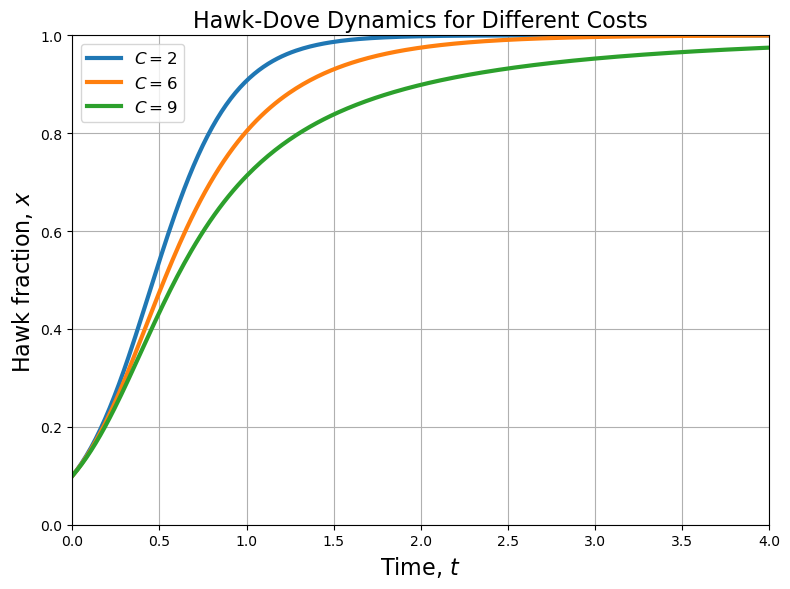

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint


# --- Parameter sweep over different costs C ---
CList = [2, 6, 9]           # Costs to fight
G = 10                      # Benefit of winning
x0 = 0.1                    # Initial fraction of hawks
tmax = 4                    # Simulation time
t = np.linspace(0, tmax, 300)

plt.figure(figsize=(8, 6))

for C in CList:
    pars = {}
    pars['G'] = G
    pars['C'] = C
    pars['A'] = np.array([[(G - C) / 2, G], [0, G / 2]])
    x = odeint(hd_model, x0, t, args=(pars,))
    plt.plot(t, x, label=f'$C={C}$', linewidth=3)

# --- Plotting ---
plt.xlabel(r'Time, $t$', fontsize=16)
plt.ylabel(r'Hawk fraction, $x$', fontsize=16)
plt.xlim([0, 4])
plt.ylim([0, 1])
plt.legend(loc='best', fontsize=12)
plt.title('Hawk-Dove Dynamics for Different Costs', fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

## Takeaway: As long as C<G, hawks dominate as they can basically justify being aggro if the cost of in fighting is worth the prize

### So.. what happens when fighting is costly?

### A hawk hawk encounter has a net negative payoff of -(C-G)/2 for the hawks, while a dove hawk encounter has a higher payoff of 0!

### Not fighting gives a better payoff 

### This should theoretically lead to co-existence, where $\dot{x} = 0$ (frequencies don't change)
### Or by looking back at our replicator dynamics equation $\dot{x}_1 = r_1(x, A)x_1 - \langle r \rangle(x, A)x_1:$ 
### $$r_1(x, A)x_1 = \langle r \rangle(x, A)x_1$$

### OR if the payoff to a hawk is equal to that of a dove --> equilibrium!

### $$P_{hawk} = P_{dove}$$
### $$ G - \left( \frac{G + C}{2} \right) x^* = \frac{G}{2}(1 - x^*) $$
### $$x^* = \frac{G}{C}$$

### Flows right into next challenge problem 

<div class="alert alert-block alert-warning">
<b>Challenge Problem:  Hawk-Dove Dynamics .</b> 
    
***

Using the values of G = 10 and C = 16, calculate the expected equilibrium, and then simulate the hawk-dove
game from multiple different initial conditions and demonstrate that all dynamics converge to the same fixed
point. Hint: use the prior code but this time modify the loop to change the initial conditions rather than the
game theoretic payoffs
</div>

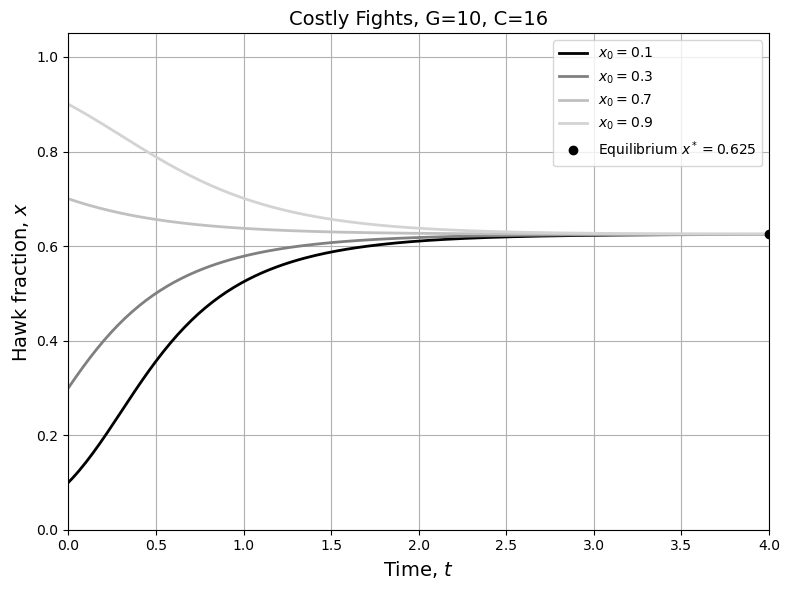

In [40]:
pars = {}

G = 10           # Gain from winning
C = 16           # Cost of fighting
pars['A'] = np.array([[(G - C) / 2, G],
                      [0, G / 2]])

tmax = 4         # Simulation duration
t = np.linspace(0, tmax, 200)

# Initial values to test
x0_list = [0.1, 0.3, 0.7, 0.9]
colors = ['black', 'gray', 'silver', 'lightgray']

# Plot trajectories from different initial conditions
plt.figure(figsize=(8, 6))
for x0, c in zip(x0_list, colors):
    x = odeint(hd_model, x0, t, args=(pars,))
    plt.plot(t, x, color=c, linewidth=2, label=f'$x_0 = {x0}$')

# Plot fixed point at x* = G /C
x_star = G / C
plt.plot(tmax, x_star, 'ko', label=f'Equilibrium $x^* = {x_star:.3f}$')

# --- Plot formatting ---
plt.title(f'Costly Fights, G={G}, C={C}', fontsize=14)
plt.xlabel('Time, $t$', fontsize=14)
plt.ylabel('Hawk fraction, $x$', fontsize=14)
plt.xlim([0, tmax])
plt.ylim([0, 1.05])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


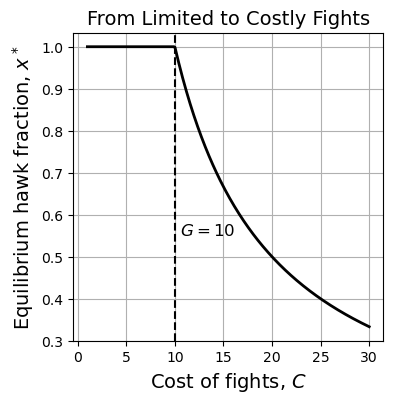

In [41]:


G = 10                            
C_vals = np.linspace(1, 30, 300)  
x_star = []                       # Initialize list to store equilibrium values

for C in C_vals:
    if C <= G:                   # cost of fighting <= payload
        x_eq = 1.0               # All hawks when cost is low
    else:                        # cost of fighting > payload
        x_eq = G / C             # Mixed strategy when cost exceeds gain
    x_star.append(x_eq)

# Convert to numpy array for plotting
x_star = np.array(x_star)

plt.figure(figsize=(4, 4))
plt.plot(C_vals, x_star, color='black', linewidth=2)

# Add a vertical line at C = G
plt.axvline(G, linestyle='--', color='black', linewidth=1.5)
plt.text(G + 0.5, 0.55, r'$G = 10$', fontsize=12)

plt.xlabel(r'Cost of fights, $C$', fontsize=14)
plt.ylabel(r'Equilibrium hawk fraction, $x^*$', fontsize=14)
plt.title(r'From Limited to Costly Fights', fontsize=14)

plt.grid(True)

plt.show()


## Stochasticity added to these games (this will be lots of me talking , feel free to read this part instead!)

### Deterministic replicator models like the Hawk-Dove game assume smooth, average dynamics in large populations 
###   but real microbial systems often involve small, discrete populations --> if we remember, small organisms have a lot of stochasticity involved!
---
###  This section introduces stochastic dynamics, where changes in population (births, deaths) occur randomly and individually, not as continuous flows
--- 
###  A stochastic event (like reproduction or death) occurs with some probability r per unit time, 
###  if  r=0.1, then the event happens roughly once every 10 time units.
---
### You can simulate such systems using discrete time steps, where at each step, an event (birth or death) happens based on the value of r
###  or nothing happens with probability 1-r
---
### The Hawk-Dove game is adapted into a stochastic birth-death model using the same payoff matrix, 
### but now considering that each interaction leads to birth (if successful) or death (if losing)
----
### What's stochastic in this game? Every birth or death occurs based on a random draw influenced by payoffs,
### meaning that even with the same parameters, different runs can lead to different outcomes
----
### The focal individual's payoff influences its chance of reproducing, and stochastic death events remove individuals, introducing fluctuations over time
---
### A finite population adds realism: outcomes vary not just due to strategy but also due to random chance — this is especially impactful in small populations.
### This is seen in the plots in this section, where small populations have wild variation while larger populations have smoother outcomes
---
### This illustrates that stochasticity dominates in small populations and gradually fades 
### and as population size increases eplicator dynamics emerge in the large-population limit
---
## Takeaway: 
### Population size and randomness can drastically shape  game outcomes, making stochastic simulations essential for realistic modeling.

## This is nice and all - but how on earth can we code this?

## Book has pseudocode, here is my take on it: 

### 1) Big overall loop for each time step: For each moment in simulated time perform a round of interactions and reproduction/death events
### 2) Repeat game N times per time step (N game runs for each t value) 
### 3) Each game consists of the following steps  4-10
### 4) Choose two random players from the population p1 (focal player) and p2 (opponent), can be hawks or doves
### 5) Determine payoff (a) based on interaction for your focal player
### 6) If a  > 0, flip a coin for birth with probability $a \times dt$
### 7) if succesful birth, make clone of p1 and replace a random  individual from population 
### 8) If a  < 0, flip a coin for death with probability $|a| \times dt$
### 9) If succesful death, make clone of random individual and replace p1
### 10) Each game (not time!) step, record number of hawks and fraction of hawks over total population 
--- 
## Now read through the code given and try and get a base code that makes sense
### Use base code built from book to build the full stochastic hawk-dove simulation
### The goal is to modularly implement the core rules from the pseudocode and base code — choosing pairs, calculating payoffs, and updating the population
### Now we can begin to ask questions like: 
#### - How does population size N influence fluctuations at equilibrium>
#### - If C<G, do hawks ALWAYS dominate? (hint: try with very few hawks initially)
#### - Does the average of many simulations match the deterministic replicator dynamics?
### Even when deterministic models predict coexistence, stochasticity can lead to fixation or extinction of one type 
### e.g., hawks may disappear entirely by chance
### The upcoming challenge problem will guide you to code this full model and explore its behavior.



<div class="alert alert-block alert-warning">
<b>Challenge Problem:  Stochastic Hawk-Dove Game.</b> 
    

</div>

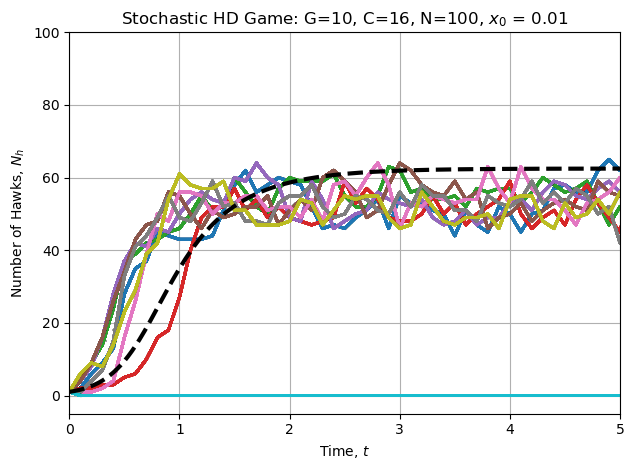

In [110]:

import matplotlib
pars = {}


pars['N'] = 100       # Population size
pars['x0'] = 1/pars['N']        # Initial hawk fraction
pars['G'] = 10           # Gain from winning
pars['C'] = 16         # Cost of fighting
pars['dt'] = 0.1      # Time step
pars['num_iter'] = 100   # Number of time steps


# A[i][j]: payoff to player i when interacting with player j
# i,j = 0 for Hawk, 1 for Dove
pars['A'] = np.array([
    [(pars['G'] - pars['C']) / 2, pars['G']],
    [0, pars['G'] / 2]
])


trials = 10
x_tot = []
t_tot = []
for i in (np.arange(trials)):
    x = [pars['x0']]                      # Track hawk fraction
    t = [0]                               # Track time
    for i in range(pars['num_iter']):
        currx = x[-1]                     # Current hawk fraction
        for j in range(pars['N']):       # One round of N games
            # Randomly select two players
            p1 = int(np.random.rand() < currx)         
            p2 = int(np.random.rand() < currx)         
            # Payoff for focal player p1
            payoff = pars['A'][p1, p2]
            if payoff > 0:
                # Birth event: focal reproduces with prob ~ payoff × dt
                if np.random.rand() < payoff * pars['dt']: #coin flip
                    if p1 == 0:  # Hawk reproduces
                        if np.random.rand() >= currx:
                            currx += 1 / pars['N']
                    else:        # Dove reproduces
                        if np.random.rand() < currx:
                            currx -= 1 / pars['N']
            elif payoff < 0:
                # Death event: focal dies with prob ~ |payoff| × dt
                if np.random.rand() < abs(payoff) * pars['dt']: #coin flip
                    if p1 == 0:  # Hawk dies
                        if np.random.rand() <= currx:
                            currx -= 1 / pars['N']
                    else:        # Dove dies
                        if np.random.rand() > currx:
                            currx += 1 / pars['N']
        # Record after N games
        x.append(currx)
        t.append(t[-1] + pars['dt'])
        #Record trajectory
        x_tot.append(np.array(x))
        t_tot.append(np.array(t))
        
        
cmap = matplotlib.colormaps['tab10']  
colors = [cmap(i / len(x_tot)) for i in range(len(x_tot))]  

for i in range(len(x_tot)):
    plt.plot(t_tot[i], x_tot[i]*pars['N'], label=f'Trial {i+1}', color = colors[i], linewidth = 2, alpha=0.7)
plt.ylim(0,pars['N'])
plt.xlabel('Time, $t$')
plt.ylabel('Number of Hawks, $N_h$')
plt.title(f'Stochastic HD Game: G={pars["G"]}, C={pars["C"]}, N={pars["N"]}, $x_0$ = {pars["x0"]}' )



### deterministic replicator dynamics 

t_det = np.linspace(0, 5, 300)
x0_det = pars['x0']
x_det = odeint(hd_model, x0_det, t_det, args=(pars,))
plt.plot(t_det, x_det[:, 0] * pars['N'], 'k--', linewidth=3, label='Replicator Dynamics')
plt.grid(True)
plt.tight_layout()
plt.xlim(0,5)
plt.ylim(-5,pars['N'])
plt.show()

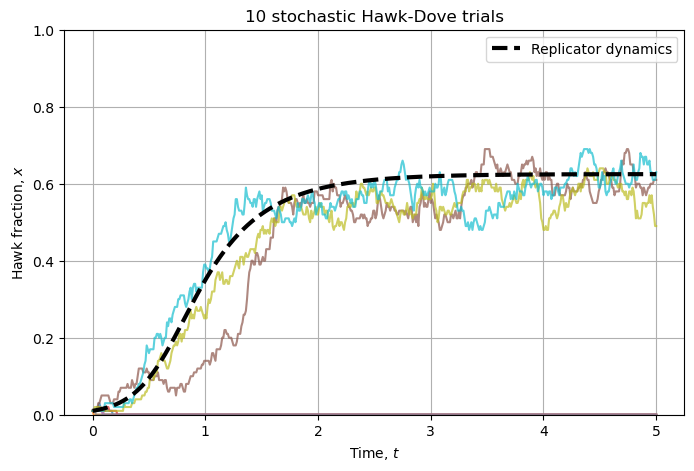

In [133]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Parameters
pars = {}
pars['N'] = 100
pars['x0'] = 1 / pars['N']
pars['G'] = 10
pars['C'] = 16
pars['dt'] = 0.01
pars['num_iter'] = 500
pars['A'] = np.array([[(pars['G'] - pars['C']) / 2, pars['G']],[0, pars['G'] / 2]])
def hd_model(x, t, pars):
    G = pars['G']
    C = pars['C']
    dxdt = x * (1 - x) * (G - C * x) / 2
    return dxdt
trials = 10
all_x = []
all_t = []
for trial in range(trials):
    currx = pars['x0']
    x = [pars['x0']]
    t = [0]
    for i in range(pars['num_iter']):
        for j in range(pars['N']):
            p1 = np.random.uniform() < currx
            tmpid1 = 1 - (p1 == 1)
            p2 = np.random.uniform() < currx
            tmpid2 = 1 - (p2 == 1)
            if p1 == 1:  # Hawk
                payoff = pars['A'][tmpid1, tmpid2]
                if payoff > 0:
                    birth = np.random.uniform() < payoff * pars['dt']
                    if birth:
                        replace_dove = np.random.uniform() >= currx
                        if replace_dove:
                            currx = currx + 1 / pars['N']
                elif payoff < 0:
                    death = np.random.uniform() < abs(payoff) * pars['dt']
                    if death:
                        replace_hawk = np.random.uniform() < currx
                        if replace_hawk:
                            currx = currx - 1 / pars['N']
            else:  # Dove
                payoff = pars['A'][tmpid1, tmpid2]
                if payoff > 0:
                    birth = np.random.uniform() < payoff * pars['dt']
                    if birth:
                        replace_hawk = np.random.uniform() < currx
                        if replace_hawk:
                            currx = currx - 1 / pars['N']
                elif payoff < 0:
                    death = np.random.uniform() < abs(payoff) * pars['dt']
                    if death:
                        replace_dove = np.random.uniform() >= currx
                        if replace_dove:
                            currx = currx + 1 / pars['N']
        currx = max(0, min(1, currx))
        x.append(currx)
        t.append(t[-1] + pars['dt'])
    all_x.append(np.array(x))
    all_t.append(np.array(t))
# Deterministic solution
t_det = np.linspace(0, all_t[0][-1], 500)
x_det = odeint(hd_model, pars['x0'], t_det, args=(pars,))
# Plot hawk fraction
plt.figure(figsize=(8,5))
for trial in range(trials):
    plt.plot(all_t[trial], all_x[trial], alpha=0.7)
plt.plot(t_det, x_det[:,0], 'k--', linewidth=3, label='Replicator dynamics')
plt.xlabel('Time, $t$')
plt.ylabel('Hawk fraction, $x$')
plt.title(f'{trials} stochastic Hawk-Dove trials')
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()


## Type VI Secretion

### Vibrio bacteria use a Type VI secretion system, like a tiny syringe/needle, to inject toxins into nearby cells. 

### Cells from the same strain protect themselves by producing an anti-toxin, though this slows their growth. 
### However cells that lack the right anti-toxin can be killed.

### Even with just these simple rules, populations can form complex spatial patterns. For example, as shown by McNally et al. (2017), a random mix of cells can gradually organize into larger, more uniform clusters over time.


### Consider the strategy-dependent payoff of two Vibrio strains which compete in a two-dimensional spatial habitat,

### 
### \begin{array}{c|cc}
\text{Player 1} \backslash \text{Player 2} & \text{Red} & \text{Blue} \\
\hline
\text{Red} & \frac{G}{2} & \frac{G - C}{2} \\
\text{Blue} & \frac{G - C}{2} & \frac{G}{2}
\end{array}
### Where G denotes the gain associated with reproducing and C denotes the cost of the Type VI killing machinery by a non-compatible type

#### Note: The use of the terms ‘red' and ‘blue' are consistent with the choice in the collaborative study of McNally et al. 

## Via the replicator dynamics notation for two-player games, 
### we can write the expected dynamics of the red type with frequency $x$ as:
\begin{equation}
\dot{x} = r_1(x, A)x - \langle r \rangle(x, A)x
\end{equation}
### where $1-x$ is the frequency of the blue type and
\begin{align}
r_1(x) &= Gx/2 + (1-x)(G-C)/2, \\
r_2(x) &= (G-C)x/2 + (1-x)G/2, \\
\langle r \rangle &= r_1x + r_2(1-x).
\end{align}

### After some algebra, this can be re-written as:
\begin{equation}
\dot{x} = x(1-x)\bigl(r_1(x) - r_2(x)\bigr)
\end{equation}

### or, after some reduction,
\begin{equation}
\dot{x} = Cx(1-x)\left(x - \frac{1}{2}\right).
\end{equation}

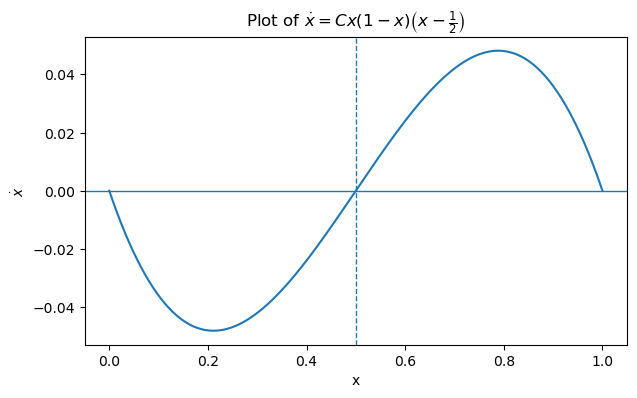

In [53]:
# parameter
C = 1.0

# x values
x = np.linspace(0, 1, 500)

# dx/dt
xdot = C * x * (1 - x) * (x - 0.5)

# plot
plt.figure(figsize=(7, 4))
plt.plot(x, xdot)
plt.axhline(0, linewidth=1)
plt.axvline(0.5, linestyle='--', linewidth=1)

plt.xlabel("x")
plt.ylabel(r"$\dot{x}$")
plt.title(r"Plot of $\dot{x} = Cx(1-x)\left(x-\frac{1}{2}\right)$")
plt.show()

### As such, we expect that for any initial conditions where x < 1/2 then the system will be driven into an ‘all-blue' state
### whereas for any initial conditions where x > 1/2 then the system will be driven into an ‘all-red' state

## Spatial T6SS Game: time to read Pseudocode and Components from Textbook!

<div class="alert alert-block alert-warning">
<b>Challenge Problem:  Periodic Boundary Conditions.</b> 
    Devise a solution to the problem of taking in a 2D position and returning a position that ‘wraps-around’ in a
torus-like sense. You should write a function that accepts a 2D position and the size of the grid and returns a
new position.

</div>

In [70]:
def pbc_reset(old_pos,L):
# function new_pos = pbc_reset(old_pos,L)
#
# Assuming periodic boundary conditions, shifts the
# positions back into the grid 0..(L-1)
    new_pos=old_pos
    for i in range(2): #range 2 as it is a 2d position, i = 0 is x and i = 1 is y
        if old_pos[i] >= L:
            new_pos[i]=0
    return new_pos

<div class="alert alert-block alert-warning">
<b>Challenge Problem:  T6SS Stochastic Spatial Model</b> 
Write your own T6SS Stochastic Spatial Dynamics. If you want this challenge without any further help, then
stop reading. In essence: spoiler alert ahead! But, if you would like some assistance, then see the solutions
that follow and copy/paste as little or as much as you’d like. Recall that you will need to setup the colormap
as noted above..

</div>

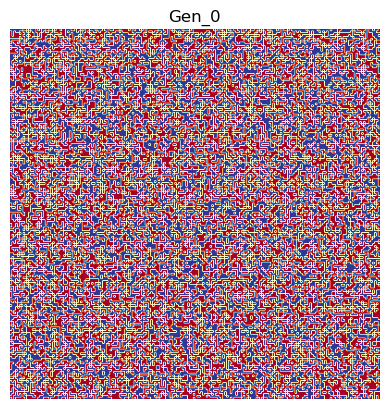

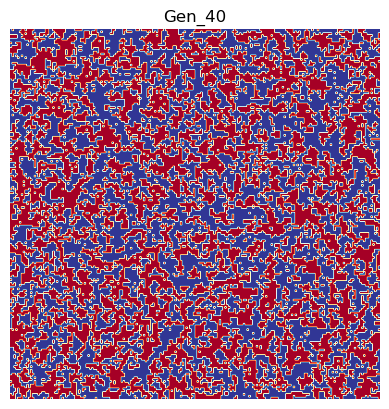

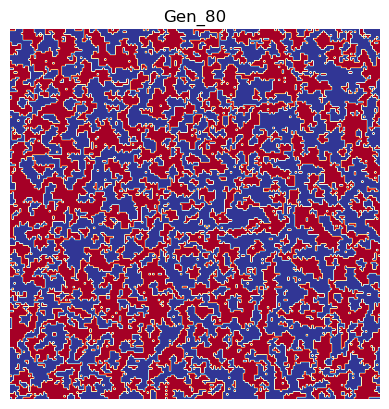

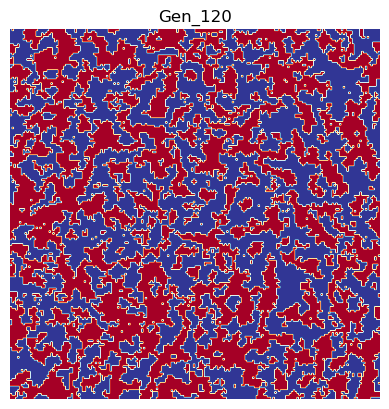

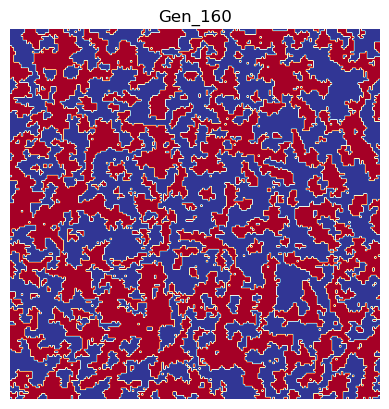

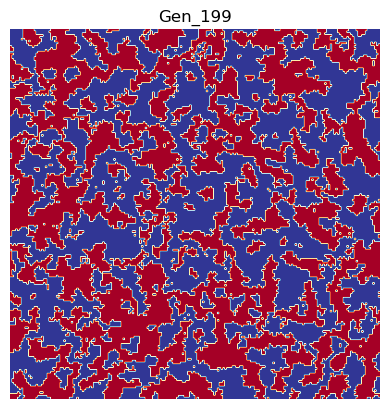

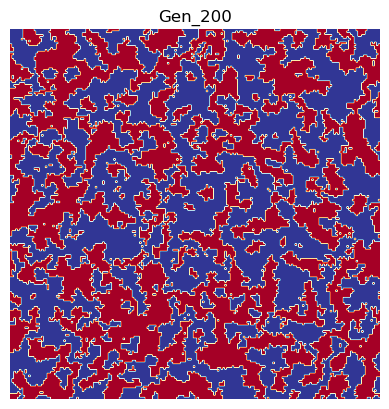

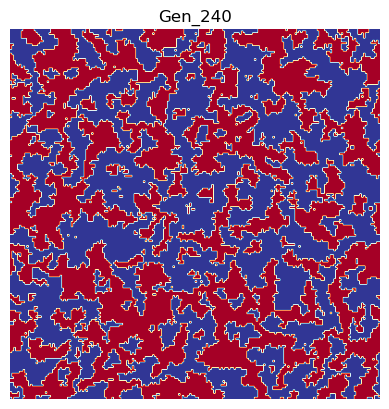

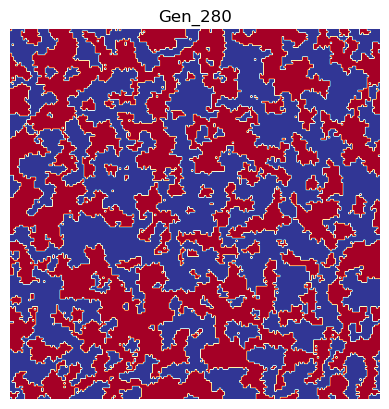

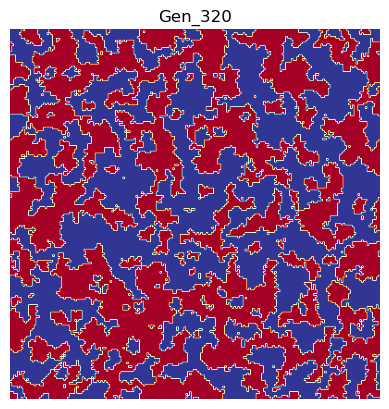

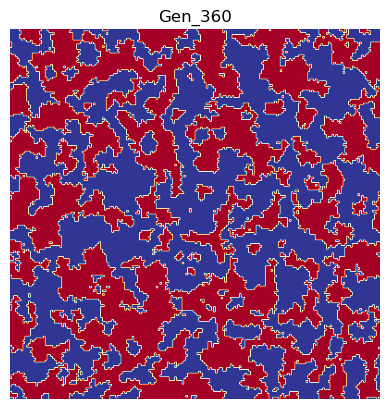

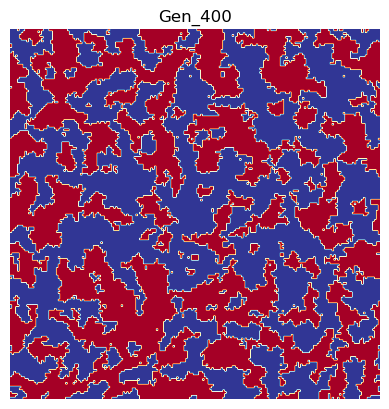

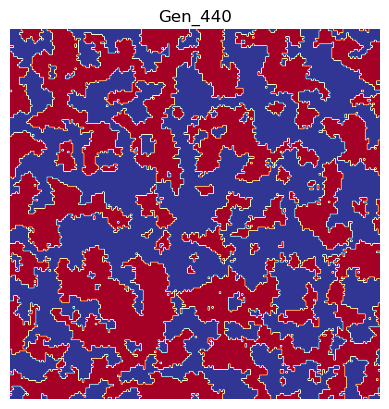

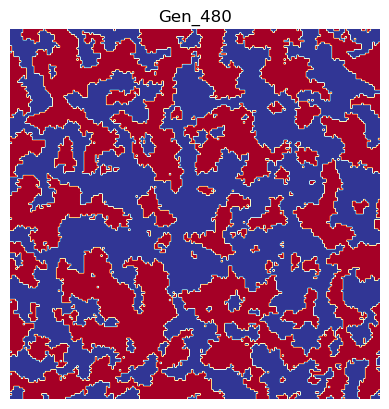

In [72]:
from __future__ import division
import matplotlib.pyplot as plt
import numpy as np
L=200
N=L**2
A=np.array([[5,-4],[-4,5]])
x1=0.5
num_iter=500
dt=0.01
tmax=dt*num_iter
moves = np.array([[-1,0],[1,0],[0,-1], [0,1]])
x=np.random.choice([0,1],[L,L],[0.5,0.5])
for i in range(num_iter):
    for j in range(N):
        foc_pos = np.random.choice(range(L),[1,2])[0]
        foc_id=x[foc_pos[0],foc_pos[1]]
        opp_pos = foc_pos + moves[np.random.choice(range(4))]
        opp_pos = pbc_reset(opp_pos,L)
        opp_id=x[opp_pos[0],opp_pos[1]]
        payoff=A[foc_id,opp_id]
        if payoff > 0:
            birth = np.random.uniform() < payoff*dt
            if birth:
                rep_pos=foc_pos+moves[np.random.choice(range(4))]
                rep_pos=pbc_reset(rep_pos,L)
                x[rep_pos[0],rep_pos[1]]=foc_id
        elif payoff < 0:
            death = np.random.uniform()<np.abs(payoff)*dt
            if death:
                rep_pos=foc_pos+moves[np.random.choice(range(4))]
                rep_pos=pbc_reset(rep_pos,L)
                x[foc_pos[0],foc_pos[1]]=x[rep_pos[0],rep_pos[1]]
    if np.mod(i,40)==0 or i==199:
        plt.figure()
        plt.axis('off')
        plt.title('Gen_{gen}'.format(gen=i))
        plt.imshow(x,cmap='RdYlBu')
        plt.savefig('Gen_{gen}.pdf'.format(gen=i), bbox_inches='tight')